# Part (b): Text EDA

Document length, vocabulary, and data quality decide which text-preprocessing comparisons are meaningful. This chapter audits AG News, a four-topic news classification corpus whose `text` field joins each article's title and description, before any normalization or representation is chosen.

Every statistic is computed on the raw published text. Markup fragments, escaped HTML, and wire-service tags therefore appear in the counts, and this chapter measures them rather than removing them; the [preprocessing chapter](04_text_preprocessing.ipynb) compares cleaning steps against this raw baseline. Descriptive statistics use the training split only. The test split contributes quality and overlap counts, so nothing about its word distribution informs later preprocessing choices.

## Load the environment

The setup cell imports the shared paths, the seed, and the text helpers, and records the package versions behind every displayed result. Randomness enters only through the seeded document sampling for the type-token ratio and the word-cloud layout. The repository README describes how to install the environment.

In [1]:
import platform
import re
from collections import Counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import kruskal
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from wordcloud import WordCloud

from preprocessing import RAW_DATA_DIR, RANDOM_STATE
from preprocessing.ag_news import (
    AG_NEWS_DATASET, AG_NEWS_REVISION, audit_text_split, count_overlap, load_ag_news,
    nearest_train_similarity,
)
from preprocessing.text import (
    WORD_PATTERN, fit_zipf, pairwise_mann_whitney, rank_frequency, sampled_ttr,
    type_token_ratio, word_tokens,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 240)
package_versions = {
    name: version(name)
    for name in [
        "numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "datasets", "wordcloud",
        "matplotlib", "seaborn",
    ]
}
package_versions["python"] = platform.python_version()
print(f"Random seed: {RANDOM_STATE}")
print(f"Raw data directory: {RAW_DATA_DIR}")
display(pd.Series(package_versions, name="version").to_frame())

Random seed: 42
Raw data directory: D:\HCMUS\DataMining\preprocessing\data\raw


,version
numpy,2.5.5
pandas,3.1.1
scipy,1.18.1
scikit-learn,1.9.1
statsmodels,0.15.0
datasets,5.2.0
wordcloud,1.9.6
matplotlib,3.11.2
seaborn,0.13.2
python,3.12.13


## Prepare data

`load_ag_news` downloads the Hugging Face dataset `fancyzhx/ag_news` at a pinned commit, or reads it from the cache under `RAW_DATA_DIR`, so the printed revision identifies the exact data. The first run needs internet access; the cache stays outside version control. The cell adds a categorical `topic` column with the label names and leaves the `text` column unchanged.

In [2]:
# The first call downloads the pinned revision (network access required); later runs read the cache.
train_raw, test_raw, label_names = load_ag_news()
LABEL_ORDER = list(label_names)


def with_topic(split):
    # Label integers index label_names; the raw text column is not modified.
    topic = split["label"].map(dict(enumerate(LABEL_ORDER)))
    return split.assign(topic=pd.Categorical(topic, categories=LABEL_ORDER))


train = with_topic(train_raw)
test = with_topic(test_raw)

print(f"Dataset: {AG_NEWS_DATASET} at revision {AG_NEWS_REVISION}")
print(f"Labels: {dict(enumerate(LABEL_ORDER))}")
print(f"Training articles: {len(train):,}; test articles: {len(test):,}")
display(train.head(3))

D:\HCMUS\DataMining\preprocessing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: fancyzhx/ag_news at revision eb185aade064a813bc0b7f42de02595523103ca4
Labels: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}
Training articles: 120,000; test articles: 7,600


,text,label,topic
0,"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.",2,Business
1,"Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets ...",2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.,2,Business


## Audit labels and define splits

Empty texts, repeated texts, and texts shared across splits distort every later comparison: duplicates overweight some articles, and a test article that also appears in training measures memorization rather than generalization. `audit_text_split` counts empty texts, exact repeats within a split, and texts that carry more than one label. `count_overlap` counts test articles whose text also occurs in training, first exactly and then after case folding and whitespace collapsing.

The assignment requires at least 10,000 labeled samples and at least two labels; the cell asserts both on the loaded data.

**Split policy.** The published 7,600-article test split stays fixed and is used only for final evaluation in the preprocessing chapter. Model selection there uses stratified five-fold cross-validation on the 120,000 training articles, shuffled with `RANDOM_STATE`, and every learned transform is fitted inside the training folds. AG News has no unlabeled split.

In [3]:
MIN_SAMPLES, MIN_LABELS = 10_000, 2

split_audit = pd.DataFrame({"train": audit_text_split(train), "test": audit_text_split(test)}).T
label_counts = pd.DataFrame(
    {
        "train": train["topic"].value_counts().reindex(LABEL_ORDER),
        "test": test["topic"].value_counts().reindex(LABEL_ORDER),
    }
)
label_shares = label_counts / label_counts.sum()
labeled_samples = len(train) + len(test)
assert labeled_samples >= MIN_SAMPLES and len(LABEL_ORDER) >= MIN_LABELS

exact_overlap = count_overlap(train, test)
normalized_overlap = count_overlap(train, test, normalize=True)

print(f"Labeled samples: {labeled_samples:,} (required >= {MIN_SAMPLES:,}); labels: {len(LABEL_ORDER)}")
display(split_audit)
display(pd.concat({"articles": label_counts, "share": label_shares}, axis=1).round(4))
print(f"Test articles whose exact text occurs in training: {exact_overlap}")
print(f"Test articles matching training after case folding and whitespace collapsing: {normalized_overlap}")

Labeled samples: 127,600 (required >= 10,000); labels: 4


,samples,empty_texts,duplicate_texts,conflicting_label_texts
train,120000,0,0,0
test,7600,0,0,0


articles       share      
            train  test train  test
topic                              
World       30000  1900  0.25  0.25
Sports      30000  1900  0.25  0.25
Business    30000  1900  0.25  0.25
Sci/Tech    30000  1900  0.25  0.25

Test articles whose exact text occurs in training: 0
Test articles matching training after case folding and whitespace collapsing: 10


### Near-duplicates across splits

Exact matching misses the commonest form of overlap in a news corpus: the same story distributed by different wire services, or the same article with altered whitespace or a different headline. `nearest_train_similarity` represents every article as a TF-IDF vector fitted on the training split, with scikit-learn's English stop-word list removed so that shared function words do not drive the score, and finds each test article's most similar training article by cosine similarity

$$
\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}^\top \mathbf{v}}{\lVert \mathbf{u} \rVert_2 \, \lVert \mathbf{v} \rVert_2},
$$

where $\mathbf{u}$ and $\mathbf{v}$ are the two TF-IDF vectors. The scan is exhaustive over all $7{,}600 \times 120{,}000$ pairs. A threshold of `NEAR_DUPLICATE_COSINE` = 0.9 flags pairs; it was set after reading example pairs at several similarity levels, so the table reports counts at other thresholds too. The label agreement column shows how often a test article and its nearest training article share a topic, which bounds how consistently near-identical text is labeled.

Median nearest-neighbor cosine: 0.528
Test articles with a training neighbor at cosine >= 0.9: 862 (11.3%)
Of these, pairs with different topics: 82 (9.5%)
Conflicting pairs between Business and Sci/Tech: 39


,test_articles,label_agreement,share_of_test
cosine,,,
"[0.0, 0.5)",3401,0.841,0.448
"[0.5, 0.8)",2758,0.923,0.363
"[0.8, 0.9)",579,0.886,0.076
"[0.9, 0.95)",319,0.922,0.042
"[0.95, 0.99)",456,0.882,0.060
"[0.99, 1.0)",87,0.966,0.011


nearest training topic,World,Sports,Business,Sci/Tech
test topic,,,,
World,0,5,11,8
Sports,3,0,0,0
Business,6,0,0,25
Sci/Tech,10,0,14,0


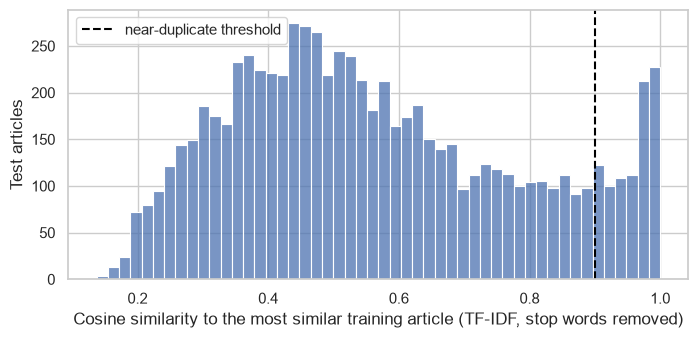

In [4]:
NEAR_DUPLICATE_COSINE = 0.9
COSINE_BINS = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0 + 1e-9]

nearest = nearest_train_similarity(train, test)
assert (nearest["train_position"] >= 0).all()  # every test article shares a word with training
nearest["test_topic"] = test["topic"]
nearest["train_topic"] = pd.Categorical(
    train["topic"].to_numpy()[nearest["train_position"]], categories=LABEL_ORDER
)
nearest["same_topic"] = nearest["test_topic"] == nearest["train_topic"]

similarity_bin = pd.cut(nearest["cosine"], COSINE_BINS, right=False)
agreement_by_similarity = nearest.groupby(similarity_bin, observed=False).agg(
    test_articles=("cosine", "size"), label_agreement=("same_topic", "mean")
)
agreement_by_similarity["share_of_test"] = agreement_by_similarity["test_articles"] / len(test)

near_duplicates = nearest[nearest["cosine"] >= NEAR_DUPLICATE_COSINE]
near_duplicate_count = len(near_duplicates)
near_duplicate_share = near_duplicate_count / len(test)
near_duplicate_conflicts = int((~near_duplicates["same_topic"]).sum())
conflict_pairs = pd.crosstab(
    near_duplicates.loc[~near_duplicates["same_topic"], "test_topic"],
    near_duplicates.loc[~near_duplicates["same_topic"], "train_topic"],
    rownames=["test topic"], colnames=["nearest training topic"],
).reindex(index=LABEL_ORDER, columns=LABEL_ORDER, fill_value=0)
conflict_share = near_duplicate_conflicts / near_duplicate_count
business_scitech_conflicts = int(
    conflict_pairs.loc["Business", "Sci/Tech"] + conflict_pairs.loc["Sci/Tech", "Business"]
)
top_bin_agreement = float(agreement_by_similarity["label_agreement"].iloc[-1])
top_bin_articles = int(agreement_by_similarity["test_articles"].iloc[-1])

print(f"Median nearest-neighbor cosine: {nearest['cosine'].median():.3f}")
print(
    f"Test articles with a training neighbor at cosine >= {NEAR_DUPLICATE_COSINE}: "
    f"{near_duplicate_count:,} ({near_duplicate_share:.1%})"
)
print(f"Of these, pairs with different topics: {near_duplicate_conflicts} ({conflict_share:.1%})")
print(f"Conflicting pairs between Business and Sci/Tech: {business_scitech_conflicts}")
display(agreement_by_similarity.round(3))
display(conflict_pairs)

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(nearest["cosine"], bins=50, ax=ax)
ax.axvline(NEAR_DUPLICATE_COSINE, color="black", linestyle="--", label="near-duplicate threshold")
ax.set_xlabel("Cosine similarity to the most similar training article (TF-IDF, stop words removed)")
ax.set_ylabel("Test articles")
ax.legend()
plt.show()

In [5]:
def show_pairs(rows, width=220):
    # Truncate long texts so the pair fits in the rendered table.
    table = pd.DataFrame(
        {
            "cosine": rows["cosine"].round(3),
            "test topic": rows["test_topic"],
            "test text": test.loc[rows.index, "text"].str.slice(0, width),
            "train topic": rows["train_topic"],
            "train text": train["text"].to_numpy()[rows["train_position"]],
        }
    )
    table["train text"] = table["train text"].str.slice(0, width)
    display(table)


# Deterministic examples: one pair per similarity band, then the most similar conflicting pairs.
example_bands = [(0.99, 1.01), (0.9, 0.95), (0.8, 0.9)]
show_pairs(
    pd.concat(
        nearest[nearest["cosine"].between(low, high, inclusive="left")]
        .sort_values("cosine", ascending=False)
        .head(1)
        for low, high in example_bands
    )
)
show_pairs(near_duplicates[~near_duplicates["same_topic"]].sort_values("cosine", ascending=False).head(4))

,cosine,test topic,test text,train topic,train text
2066,1.00,Sports,NFL Wrap: Manning Wins MVP Battle as Colts Overcome Titans NEW YORK (Reuters) - Peyton Manning threw for 254 yards and two touchdowns to win his showdown with fellow co-MVP Steve McNair as the Indianapolis Colts beat,Sports,NFL Wrap: -Manning Wins MVP Battle as Colts Overcome Titans NEW YORK (Reuters) - Peyton Manning threw for 254 yards and two touchdowns to win his showdown with fellow co-MVP Steve McNair as the Indianapolis Colts beat
3662,0.95,World,"Oil Prices, Earnings Send Stocks Lower NEW YORK - Investors sent stocks lower Tuesday as oil prices crossed another milestone, \$54 per barrel. Earnings reports from heavyweights Johnson Johnson and Merrill Lynch Co.",World,"Stocks Slide on Oil Prices, Earnings NEW YORK - Investors sent stocks lower Tuesday as oil prices crossed another milestone, \$54 per barrel. Earnings reports from heavyweights Johnson Johnson and Merrill Lynch Co..."
4582,0.90,Sci/Tech,Cassini to Look at Saturn's Giant Moon (AP) AP - The theory that Saturn's giant moon Titan has oceans or seas of liquid methane and ethane faced its best test yet Tuesday.,Sci/Tech,"Cassini takes a close-up look at Saturn #39;s giant moon Titan PASADENA, Calif. - The theory that Saturn #39;s giant moon Titan has oceans or seas of liquid methane and ethane faced its best test yet Tuesday."


,cosine,test topic,test text,train topic,train text
5935,1.000,World,Swedes beam poetry into outer space (Reuters) Reuters - Swedish poets have broadcast their work into outer space by radio to give alien life forms -- if they exist -- a taste\of earthling literature.,Sci/Tech,Swedes Beam Poetry Into Outer Space (Reuters) Reuters - Swedish poets have broadcast their\work into outer space by radio to give alien life forms -- if\they exist -- a taste of earthling literature.
3970,0.996,Business,"Wi-Fi successor is called high-speed hype -- for now SAN FRANCISCO -- At virtually every turn, Intel Corp. executives are heaping praise on an emerging long-range wireless technology known as WiMAX, which can blanket ent",Sci/Tech,"Wi-Fi Successor Called High-Speed Hype, for Now SAN FRANCISCO (Reuters) - At virtually every turn, Intel Corp. executives are heaping praise on an emerging long-range wireless technology known as WiMAX, which can blan"
967,0.992,World,"Maddux Wins No. 302, Baker Wins No. 1,000 Greg Maddux pitched the Chicago Cubs into the lead in the NL wild-card race and gave Dusty Baker a win to remember. Maddux threw seven shutout innings for his 302nd career win, B",Sports,"Maddux Wins No. 302, Baker Wins No. 1,000 (AP) AP - Greg Maddux pitched the Chicago Cubs into the lead in the NL wild-card race and gave Dusty Baker a win to remember. Maddux threw seven shutout innings for his 302nd car"
240,0.990,Sci/Tech,Bill Clinton Helps Launch Search Engine Former president Bill Clinton on Monday helped launch a new Internet search company backed by the Chinese government which says its technology uses artificial intelligence to produ,Business,Bill Clinton Helps Launch Search Engine NEW YORK - Former president Bill Clinton on Monday helped launch a new Internet search company backed by the Chinese government which says its technology uses artificial intelligen


AG News meets the assignment's size requirements with {eval}`f"{labeled_samples:,}"` labeled articles in {eval}`len(LABEL_ORDER)` topics. Both splits are exactly balanced, with 30,000 training and 1,900 test articles per topic (`label_counts`), so accuracy and macro-averaged scores agree up to per-class differences and no resampling is needed. No text is empty, repeated within its split, or labeled twice (`split_audit`). Exact matching finds {eval}`exact_overlap` test articles in the training split, and case and whitespace normalization finds {eval}`normalized_overlap`.

Exact matching understates the overlap. {eval}`f"{near_duplicate_count:,}"` test articles ({eval}`f"{near_duplicate_share:.1%}"`) have a training article at cosine similarity {eval}`NEAR_DUPLICATE_COSINE` or higher. The example pairs show what these are: the same wire story with a reworded headline, with a wire tag added or removed, or with different whitespace and entity encoding. The example between 0.8 and 0.9 reports the same event in different words. That is related content rather than a copy, so 0.9 is a cautious boundary for "near-duplicate", and the flagged count is a lower bound on test articles whose story also appears in training.

Label agreement matters more than the count. Of the near-duplicate pairs, {eval}`near_duplicate_conflicts` ({eval}`f"{conflict_share:.1%}"`) carry different topics, and even among the {eval}`top_bin_articles` pairs at cosine 0.99 or above only {eval}`f"{top_bin_agreement:.1%}"` agree. {eval}`business_scitech_conflicts` of the {eval}`near_duplicate_conflicts` conflicts are between Business and Sci/Tech, where technology-company news fits both topics; other examples include a baseball report labeled World. Near-identical text with different labels is label noise that no preprocessing can remove, so classifiers trained here should not be expected to reach perfect accuracy, and part of every test error will come from articles like these.

**Handling.** No article is removed. The published test split stays intact so results remain comparable with other work on AG News, and `nearest_train_similarity` can recompute the flags wherever a result needs a sensitivity check on the test articles without a near-copy in training. Two limits remain. Near-duplicates within the training split were not searched (that would be $120{,}000^2/2$ pairs), so cross-validation folds may place near-copies on both sides and score slightly higher than the test split. TF-IDF cosine also detects shared wording, not shared meaning, so paraphrased copies are missed.

## Audit markup and source markers

The raw text was scraped from web news feeds, so it carries encoding residue as well as words. These fragments become tokens under any tokenizer and would distort vocabulary sizes, frequency tables, and the Zipf curve, so their prevalence is measured before those statistics are read. The patterns below are regular expressions applied to the unmodified text:

- **Escaped HTML entities** such as `&lt;`, `&gt;`, `&amp;`, and `&quot;`, and **escaped HTML tags** such as `&lt;A HREF=...&gt;`, which are links stored as text.
- **Entities missing their ampersand**, such as `#39;` for an apostrophe or `#36;` for a dollar sign, and bare `quot;`. The ampersand was lost upstream, so a standard HTML decoder does not repair them.
- **Literal backslashes**, which stand where the source had line breaks and often join two words (`Friday\but`).
- **URLs**, **mentions** (`@name`), and **hashtags** (`#tag`), which the assignment's normalization pipeline must handle.
- **Wire-service tags** `(Reuters)`, `(AP)`, and `(AFP)`. These are content, not residue, but if their frequency differs by topic they can act as a label shortcut that has nothing to do with the article's subject.

The table reports the share of articles that contain each pattern at least once.

In [6]:
MARKUP_PATTERNS = {
    "escaped HTML entity": r"&(?:lt|gt|amp|quot);",
    "escaped HTML tag": r"&lt;/?[A-Za-z]",
    "entity missing & (#39;)": r"(?<!&)#(?:\d+|x[0-9A-Fa-f]+);",
    "named entity missing & (quot;)": r"(?<![&\w])(?:quot|lt|gt|amp);",
    "literal backslash": r"\\",
    "URL": r"https?://|www\.",
    "@mention": r"(?<![\w.])@\w+",
    # Excludes hex entities that lost their "&", such as "#x2014;".
    "hashtag": r"(?<![\w&])#(?!x[0-9A-Fa-f]+;)[A-Za-z]\w*",
    "wire tag (Reuters)": r"\(Reuters\)",
    "wire tag (AP)": r"\(AP\)",
    "wire tag (AFP)": r"\(AFP\)",
}

markup_flags = {
    name: pd.DataFrame(
        {label: split["text"].str.contains(pattern, regex=True) for label, pattern in MARKUP_PATTERNS.items()}
    )
    for name, split in [("train", train), ("test", test)]
}
markup_prevalence = pd.concat(
    [
        markup_flags["train"].mean().rename("train"),
        markup_flags["test"].mean().rename("test"),
        markup_flags["train"].groupby(train["topic"], observed=True).mean().T,
    ],
    axis=1,
)
markup_prevalence.insert(0, "train_articles", markup_flags["train"].sum())
max_split_prevalence_gap = float((markup_prevalence["train"] - markup_prevalence["test"]).abs().max())
any_markup_residue = markup_flags["train"].iloc[:, :5].any(axis=1)
markup_residue_share = float(any_markup_residue.mean())
# Escaped links are long; compare raw character lengths with and without them.
has_escaped_tag = markup_flags["train"]["escaped HTML tag"]
escaped_tag_length = train["text"].str.len().groupby(has_escaped_tag).median()
escaped_tag_length.index = escaped_tag_length.index.map({False: "without escaped tag", True: "with escaped tag"})

print(f"Training articles with at least one markup residue pattern (first five rows): {markup_residue_share:.1%}")
print("Share of articles containing each pattern (train, test, and training articles by topic):")
display(markup_prevalence.round(4))
print(f"Largest train-test difference in prevalence: {max_split_prevalence_gap:.4f}")
print("Median raw character length of training articles:")
display(escaped_tag_length.to_frame("median characters").T)

markup_examples = pd.Series(
    {
        label: train.loc[markup_flags["train"][label], "text"].iloc[0][:200]
        for label in MARKUP_PATTERNS
        if markup_flags["train"][label].any()
    },
    name="first matching training article",
)
display(markup_examples.to_frame())

Training articles with at least one markup residue pattern (first five rows): 40.3%
Share of articles containing each pattern (train, test, and training articles by topic):


,train_articles,train,test,World,Sports,Business,Sci/Tech
escaped HTML entity,5243,0.0437,0.0397,0.0319,0.0211,0.0746,0.0472
escaped HTML tag,5241,0.0437,0.0396,0.0319,0.0210,0.0746,0.0472
entity missing & (#39;),31361,0.2613,0.2620,0.2099,0.3313,0.2814,0.2228
named entity missing & (quot;),6181,0.0515,0.0513,0.0439,0.0427,0.0671,0.0524
literal backslash,13146,0.1096,0.1063,0.0570,0.0308,0.2214,0.1289
URL,1847,0.0154,0.0130,0.0000,0.0001,0.0513,0.0101
@mention,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
hashtag,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
wire tag (Reuters),12801,0.1067,0.1021,0.1300,0.0475,0.1852,0.0641
wire tag (AP),8290,0.0691,0.0692,0.0977,0.1033,0.0079,0.0674


Largest train-test difference in prevalence: 0.0048
Median raw character length of training articles:


escaped HTML tag,without escaped tag,with escaped tag
median characters,230.0,317.0


,first matching training article
escaped HTML entity,HP: The Adaptive Enterprise that can't adapt &lt;strong&gt;Opinion&lt;/strong&gt; SAP hardly to blame
escaped HTML tag,HP: The Adaptive Enterprise that can't adapt &lt;strong&gt;Opinion&lt;/strong&gt; SAP hardly to blame
entity missing & (#39;),"Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\but stayed near lows for the year as oil prices surged past #36;46\a barrel, offsetting a positive outlook"
named entity missing & (quot;),"Letters Target the abusers of legal weapons We can all share the outrage, expressed by columnist Steve Bailey (''Summer Sizzler, quot; Aug. 11), at the killings in the city's poor neighborhoods. But t"
literal backslash,"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again."
URL,"AMD starts shipping 90-nanometer chips to customers Advanced Micro Devices Inc.'s (AMD Inc.'s) 90-nanometer notebook processors are on their way to customers, according to a research note published by"
hashtag,In AD 2004 \\(Second term was beginning.)\\&lt;Kerry&gt; What happen ?\\&lt;Edwards&gt; Somebody set up us the bomb.\\&lt;Edwards&gt; We get Ohio exit poll.\\&lt;Kerry&gt; What you say?!\\&lt;Edwards&
wire tag (Reuters),"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again."
wire tag (AP),"Money Funds Fell in Latest Week (AP) AP - Assets of the nation's retail money market mutual funds fell by #36;1.17 billion in the latest week to #36;849.98 trillion, the Investment Company Institute"
wire tag (AFP),"Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world oil prices, toppling records and straining wallets, present a new economic menace barely three months bef"


Encoding residue is common: {eval}`f"{markup_residue_share:.1%}"` of training articles contain at least one of the first five patterns. Entities that lost their ampersand are the most frequent ({eval}`f"{markup_prevalence.loc['entity missing & (#39;)', 'train']:.1%}"` of training articles), mostly `#39;` for an apostrophe and `#36;` for a dollar sign. Literal backslashes follow at {eval}`f"{markup_prevalence.loc['literal backslash', 'train']:.1%}"`. Escaped HTML appears in {eval}`f"{markup_prevalence.loc['escaped HTML tag', 'train']:.1%}"` of articles, and the entity and tag rows are almost identical, so escaped entities occur inside escaped tags rather than on their own. The tags are mainly Reuters stock-quote links, and they are long: articles containing one have a median of {eval}`int(escaped_tag_length['with escaped tag'])` characters against {eval}`int(escaped_tag_length['without escaped tag'])` without. URLs occur in {eval}`f"{markup_prevalence.loc['URL', 'train']:.1%}"` of articles. Mentions and hashtags are essentially absent ({eval}`int(markup_prevalence.loc['@mention', 'train_articles'])` and {eval}`int(markup_prevalence.loc['hashtag', 'train_articles'])` training articles), so those normalization steps will have almost nothing to act on in this corpus.

The test split shows the same prevalence as the training split for every pattern, with a largest difference of {eval}`f"{max_split_prevalence_gap * 100:.1f}"` percentage points, so the residue comes from the same source process, and cleaning rules designed on training text should transfer to test text.

Residue is not spread evenly across topics. Backslashes occur in {eval}`f"{markup_prevalence.loc['literal backslash', 'Business']:.1%}"` of Business articles but {eval}`f"{markup_prevalence.loc['literal backslash', 'Sports']:.1%}"` of Sports articles, and URLs are confined almost entirely to Business and Sci/Tech. Cleaning therefore changes some topics' token distributions more than others. Wire tags are also strongly topic-dependent: `(Reuters)` appears in {eval}`f"{markup_prevalence.loc['wire tag (Reuters)', 'Business']:.1%}"` of Business articles and {eval}`f"{markup_prevalence.loc['wire tag (Reuters)', 'Sports']:.1%}"` of Sports articles, while `(AP)` appears in {eval}`f"{markup_prevalence.loc['wire tag (AP)', 'Sports']:.1%}"` of Sports and {eval}`f"{markup_prevalence.loc['wire tag (AP)', 'Business']:.1%}"` of Business articles. A classifier can use the source as weak evidence of the topic without reading the article, which inflates scores in a way that would not carry over to text from other sources.

## Compare document lengths

Length differences between topics matter for two reasons. Longer documents yield more tokens and larger sparse vectors, and a classifier can partly separate topics by length alone, which would make length-sensitive preprocessing look more or less useful for reasons unrelated to meaning.

**Counting convention.** The word count is the number of whitespace-separated pieces of the raw text (`str.split()`), so `#39;s` or `Friday\but` count as one word and punctuation attached to a word is not split off. The character count is the Python string length, including spaces and markup. Both are computed on the 120,000 training articles.

**Tests.** Length distributions are right-skewed, so the comparison uses rank-based tests rather than means. The Kruskal-Wallis test checks first whether any topic differs: its null hypothesis is that all four topics have the same length distribution, and its effect size is $\varepsilon^2 = H/(n-1)$, where $H$ is the test statistic and $n$ the number of articles. The Mann-Whitney U test then compares each of the six topic pairs. For topics $A$ and $B$ the null hypothesis is $P(X_A > X_B) = P(X_A < X_B)$ and the alternative is two-sided. With six tests, Holm's step-down correction keeps the family-wise error rate at $\alpha = 0.05$.

With 30,000 articles per topic, even negligible differences give tiny p-values, so the effect size carries the practical conclusion. The rank-biserial correlation

$$
r = \frac{2U_A}{n_A n_B} - 1 = P(X_A > X_B) - P(X_A < X_B)
$$

uses $U_A$, the Mann-Whitney statistic of topic $A$, and $n_A$, $n_B$, the two sample sizes, with ties counted as half. It ranges from $-1$ to $1$; $r = 0$ means neither topic tends to be longer, and $(r+1)/2$ is the probability that a random article from $A$ is longer than one from $B$.

Training-split length summary by topic (words = whitespace pieces, characters = string length):


topic               World   Sports  Business  Sci/Tech
words      count  30000.0  30000.0   30000.0   30000.0
           mean      38.9     37.8      37.5      37.2
           std       10.3      8.9       8.1      12.4
           min       11.0      8.0       8.0       8.0
           25%       33.0     32.0      32.0      30.0
           50%       39.0     37.0      37.0      36.0
           75%       44.0     42.0      42.0      42.0
           99%       75.0     66.0      58.0      84.0
           max      145.0    151.0     134.0     177.0
characters count  30000.0  30000.0   30000.0   30000.0
           mean     242.6    224.7     241.4     237.2
           std       63.6     50.5      64.3      82.2
           min      100.0    100.0     100.0     100.0
           25%      204.0    190.0     204.0     190.0
           50%      243.0    220.0     236.0     230.0
           75%      276.0    251.0     267.0     268.0
           99%      462.0    392.0     486.0     551.0
           max      865.0    853.0    1006.0    1012.0

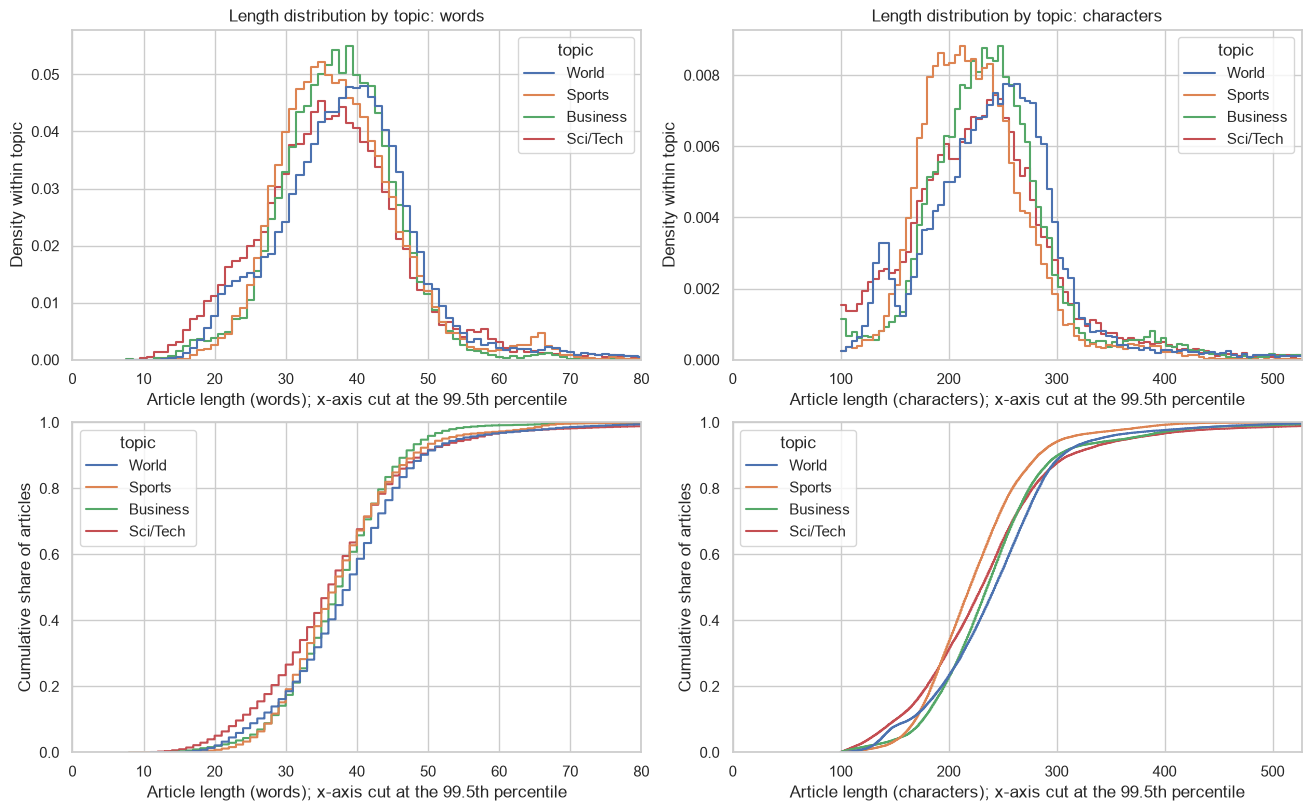

In [7]:
ALPHA = 0.05
LENGTH_MEASURES = ["words", "characters"]

lengths = pd.DataFrame(
    {
        "topic": train["topic"],
        "words": train["text"].str.split().str.len(),
        "characters": train["text"].str.len(),
    }
)
length_summary = (
    lengths.groupby("topic", observed=True)[LENGTH_MEASURES]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.99])
    .T
)
print("Training-split length summary by topic (words = whitespace pieces, characters = string length):")
display(length_summary.round(1))

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for column, measure in enumerate(LENGTH_MEASURES):
    upper = lengths[measure].quantile(0.995)
    # Word counts are integers, so one bin per value avoids aliasing; characters use 5-character bins.
    binning = {"discrete": True} if measure == "words" else {"binwidth": 5}
    sns.histplot(
        data=lengths[lengths[measure] <= upper], x=measure, hue="topic", hue_order=LABEL_ORDER,
        element="step", fill=False, stat="density", common_norm=False, ax=axes[0, column], **binning,
    )
    sns.ecdfplot(data=lengths, x=measure, hue="topic", hue_order=LABEL_ORDER, ax=axes[1, column])
    for row in range(2):
        axes[row, column].set_xlim(0, upper)
        axes[row, column].set_xlabel(f"Article length ({measure}); x-axis cut at the 99.5th percentile")
    axes[0, column].set_title(f"Length distribution by topic: {measure}")
for column in range(2):
    axes[0, column].set_ylabel("Density within topic")
    axes[1, column].set_ylabel("Cumulative share of articles")
plt.show()

Kruskal-Wallis tests across the 4 topics (alpha = 0.05):


,H,p_value,epsilon_squared
measure,,,
words,865.548320,2.628191e-187,0.007213
characters,2215.367005,0.000000e+00,0.018462


Pairwise Mann-Whitney U tests with Holm-adjusted p-values:


,group_a,group_b,n_a,n_b,median_a,median_b,u_statistic,p_value,p_holm,rank_biserial,prob_a_longer,reject_h0
measure,,,,,,,,,,,,
words,World,Sports,30000,30000,39,37,4.878e+08,3.15e-71,1.57e-70,+0.084,0.542,True
words,World,Business,30000,30000,39,37,4.82e+08,1.55e-51,4.65e-51,+0.071,0.536,True
words,World,Sci/Tech,30000,30000,39,36,5.084e+08,2.75e-167,1.65e-166,+0.130,0.565,True
words,Sports,Business,30000,30000,37,37,4.404e+08,5.45e-06,5.45e-06,-0.021,0.489,True
words,Sports,Sci/Tech,30000,30000,37,36,4.767e+08,2.02e-36,4.05e-36,+0.059,0.530,True
words,Business,Sci/Tech,30000,30000,37,36,4.836e+08,1.51e-56,6.04e-56,+0.075,0.537,True
characters,World,Sports,30000,30000,243,220,5.435e+08,0.00e+00,0.00e+00,+0.208,0.604,True
characters,World,Business,30000,30000,243,236,4.721e+08,2.35e-25,2.35e-25,+0.049,0.525,True
characters,World,Sci/Tech,30000,30000,243,230,4.968e+08,1.07e-107,4.26e-107,+0.104,0.552,True


Rejected null hypotheses: 12 of 12


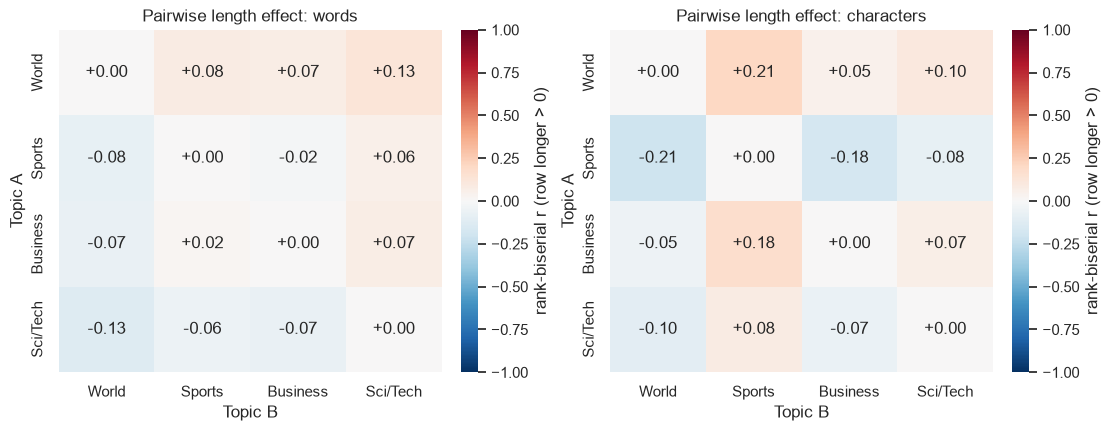

In [8]:
kruskal_tests = pd.DataFrame(
    [
        {
            "measure": measure,
            "H": (result := kruskal(*[lengths.loc[lengths["topic"] == t, measure] for t in LABEL_ORDER])).statistic,
            "p_value": result.pvalue,
            "epsilon_squared": result.statistic / (len(lengths) - 1),
        }
        for measure in LENGTH_MEASURES
    ]
).set_index("measure")

length_tests = pd.concat(
    {m: pairwise_mann_whitney(lengths[m], lengths["topic"], order=LABEL_ORDER) for m in LENGTH_MEASURES},
    names=["measure", "pair"],
).droplevel("pair")
length_tests["prob_a_longer"] = (length_tests["rank_biserial"] + 1) / 2
length_tests["reject_h0"] = length_tests["p_holm"] < ALPHA



def largest_effect(measure):
    pairs = length_tests.loc[measure].reset_index(drop=True)
    return pairs.loc[pairs["rank_biserial"].abs().idxmax()]


largest_word_effect = largest_effect("words")
largest_char_effect = largest_effect("characters")
pairs_rejected = int(length_tests["reject_h0"].sum())

print(f"Kruskal-Wallis tests across the {len(LABEL_ORDER)} topics (alpha = {ALPHA}):")
display(kruskal_tests)
print("Pairwise Mann-Whitney U tests with Holm-adjusted p-values:")
display(
    length_tests[
        ["group_a", "group_b", "n_a", "n_b", "median_a", "median_b", "u_statistic",
         "p_value", "p_holm", "rank_biserial", "prob_a_longer", "reject_h0"]
    ].style.format(
        {"u_statistic": "{:.4g}", "p_value": "{:.2e}", "p_holm": "{:.2e}",
         "rank_biserial": "{:+.3f}", "prob_a_longer": "{:.3f}", "median_a": "{:.0f}", "median_b": "{:.0f}"}
    )
)
print(f"Rejected null hypotheses: {pairs_rejected} of {len(length_tests)}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, measure in zip(axes, LENGTH_MEASURES):
    pairs = length_tests.loc[measure]
    matrix = pd.DataFrame(0.0, index=LABEL_ORDER, columns=LABEL_ORDER)
    for _, row in pairs.iterrows():
        matrix.loc[row["group_a"], row["group_b"]] = row["rank_biserial"]
        matrix.loc[row["group_b"], row["group_a"]] = -row["rank_biserial"]
    sns.heatmap(matrix, annot=True, fmt="+.2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
                cbar_kws={"label": "rank-biserial r (row longer > 0)"})
    ax.set_title(f"Pairwise length effect: {measure}")
    ax.set_xlabel("Topic B")
    ax.set_ylabel("Topic A")
plt.show()

AG News articles are short. The median training article has {eval}`int(lengths['words'].median())` whitespace words and {eval}`int(lengths['characters'].median())` characters, and 99% of articles in every topic have at most {eval}`int(length_summary.loc[('words', '99%')].max())` words (`length_summary`). The distributions are right-skewed, with a few articles several times longer than the median. Every topic has a minimum of exactly {eval}`int(lengths['characters'].min())` characters; the length floor is shared by all four topics, which suggests that the corpus was filtered by length when it was built, so the lower tail is truncated rather than natural.

The Kruskal-Wallis test rejects equal length distributions for both measures, and all {eval}`pairs_rejected` of {eval}`len(length_tests)` pairwise Mann-Whitney nulls are rejected after Holm correction at $\alpha$ = {eval}`ALPHA`. These rejections reflect 30,000 articles per topic rather than large differences. Topic explains a small share of the rank variance ($\varepsilon^2$ = {eval}`f"{kruskal_tests.loc['words', 'epsilon_squared']:.3f}"` for words and {eval}`f"{kruskal_tests.loc['characters', 'epsilon_squared']:.3f}"` for characters). The largest word-count effect, {eval}`largest_word_effect['group_a']` against {eval}`largest_word_effect['group_b']`, is $r$ = {eval}`f"{largest_word_effect['rank_biserial']:+.3f}"`: a random {eval}`largest_word_effect['group_a']` article is longer than a random {eval}`largest_word_effect['group_b']` article with probability {eval}`f"{largest_word_effect['prob_a_longer']:.3f}"`, little better than a coin toss.

Characters separate the topics more than words. The largest character effect is {eval}`largest_char_effect['group_a']` against {eval}`largest_char_effect['group_b']` ($r$ = {eval}`f"{largest_char_effect['rank_biserial']:+.3f}"`). Sports and Business have the same median word count, yet Sports articles are shorter in characters, so Sports articles use shorter words on average; scores, short names, and sports vocabulary are plausible reasons, though this chapter does not test them. The counting convention also matters: escaped links add many characters and few whitespace words, which helps explain why Business and Sci/Tech have the longest upper tails in characters.

Length is a weak signal for topic in this corpus, so length differences are unlikely to drive differences between preprocessing methods.

## Describe vocabulary and frequent words

**Token convention.** Vocabulary statistics use `word_tokens`, which case-folds the raw text and extracts runs of letters or digits, keeping internal apostrophes (`bush's`). Every other character splits tokens, so `U.S.` becomes `u` and `s`, and the broken entity `#39;s` becomes `39` and `s`. This rule is a counting convention for description, not a preprocessing choice; the tokenizers compared in the preprocessing chapter use different boundaries and yield different counts. The rule differs from the whitespace word count above, so token totals and word counts are not interchangeable.

**Frequency tables.** The required top-50 tables count raw tokens per topic, with ties broken alphabetically. Because function words dominate any raw ranking, a second view drops scikit-learn's English stop-word list, single-character tokens, and all-digit tokens. That filter is applied for display only, to show topic-specific vocabulary in tables and word clouds; it leaves markup fragments such as `quot` and `lt` in place, and stop-word removal itself is evaluated in the preprocessing chapter.

**Type-token ratio.** For a token sample with $N$ tokens and $V$ distinct types,

$$
\mathrm{TTR} = \frac{V}{N}.
$$

TTR falls as $N$ grows, because common words keep recurring while new types appear ever more slowly. Topics with more text would therefore look less diverse for that reason alone, so whole-topic TTR is reported for reference and the comparison uses a fixed token budget instead: each of `TTR_DRAWS` draws shuffles a topic's articles with a seeded generator, concatenates them until exactly $N$ tokens are collected, and computes $V/N$. No training article has zero tokens, so no empty-document rule is needed; the cell asserts this.

In [9]:
TOP_K = 50
DISPLAY_STOP_WORDS = frozenset(ENGLISH_STOP_WORDS)


def is_content_token(token):
    # Display filter only: drop stop words, single characters, and pure digit strings.
    return len(token) > 1 and not token.isdigit() and token not in DISPLAY_STOP_WORDS


train_tokens = train["text"].map(word_tokens)
tokens_per_article = train_tokens.str.len()
empty_token_articles = int((tokens_per_article == 0).sum())
assert empty_token_articles == 0

topic_counts = {
    topic: Counter(token for doc in train_tokens[train["topic"] == topic] for token in doc)
    for topic in LABEL_ORDER
}
corpus_counts = sum(topic_counts.values(), Counter())
topic_ranks = {topic: rank_frequency(counts) for topic, counts in topic_counts.items()}
content_ranks = {
    topic: ranks[ranks["token"].map(is_content_token)].reset_index(drop=True)
    for topic, ranks in topic_ranks.items()
}


def top_table(ranks_by_topic):
    table = pd.concat(
        {t: r.head(TOP_K).set_index(np.arange(1, TOP_K + 1))[["token", "frequency"]] for t, r in ranks_by_topic.items()},
        axis=1,
    )
    table.index.name = "rank"
    return table


top_words = top_table(topic_ranks)
top_content_words = top_table(content_ranks)

top_stop_word_share = pd.Series(
    {t: top_words[(t, "token")].isin(DISPLAY_STOP_WORDS).mean() for t in LABEL_ORDER},
    name=f"stop-word share of raw top {TOP_K}",
)
content_sets = {t: set(top_content_words[(t, "token")]) for t in LABEL_ORDER}
content_top_overlap = pd.DataFrame(
    [[len(content_sets[a] & content_sets[b]) / len(content_sets[a] | content_sets[b]) for b in LABEL_ORDER] for a in LABEL_ORDER],
    index=LABEL_ORDER, columns=LABEL_ORDER,
)
MARKUP_TOKENS = ["39", "quot", "lt", "gt", "amp", "36", "href", "a"]
corpus_rank = rank_frequency(corpus_counts).set_index("token")
markup_token_ranks = corpus_rank.reindex(MARKUP_TOKENS)[["rank", "frequency"]]

print(f"Training tokens: {tokens_per_article.sum():,}; distinct types: {len(corpus_counts):,}")
print(f"Raw top-{TOP_K} tokens per topic (frequency = token count in the topic's training articles):")
display(top_words)
display(top_stop_word_share.to_frame().T.round(2))
print("Corpus rank of tokens that markup fragments produce (some, such as 'a', are also real words):")
display(markup_token_ranks.T)

Training tokens: 4,733,956; distinct types: 67,670
Raw top-50 tokens per topic (frequency = token count in the topic's training articles):


World             Sports             Business             Sci/Tech  \
           token frequency    token frequency      token frequency      token   
rank                                                                            
1            the     49041      the     63390        the     44820        the   
2             in     32217       to     27683         to     30221         to   
3             to     31139        a     26073          a     29097          a   
4              a     30819       in     24050         of     22781         of   
5             of     28983       of     20393         in     22300        and   
6            and     17659      and     15859        and     17190         in   
7             on     16209       39     14826         on     16780        for   
8            for     11638      for     13903          s     12671         on   
9              s      9557       on     12359        for     12165       that   
10            39      8923        s     10192         39     11743         39   
11          said      7745       at      9358        its      9567         is   
12          that      6788     with      8412    reuters      8717        its   
13            at      6271      his      7851         as      8299          s   
14            as      6232       ap      6261       said      7311       with   
15          with      6064       as      5755       that      7308        new   
16            ap      5786      was      5328        new      6632         it   
17            an      5678       is      4851         it      6399        has   
18            by      5511       he      4578        oil      6368         by   
19          iraq      5471    after      4558         us      6100         as   
20       reuters      5423     that      4494         by      6041  microsoft   
21           his      4883     game      4269         gt      5262         at   
22          from      4685    first      4246         lt      5234       will   
23           has      4595      new      4163       with      5052       from   
24           was      4459     over      4159         is      4925         gt   
25         after      4361      has      4134       from      4848         lt   
26            is      4353       by      4002         at      4778         an   
27     president      4246    their      3765     stocks      4518        are   
28            us      4130     from      3742        inc      4419         ap   
29           two      3589       it      3741     prices      4226       said   
30           new      3479   season      3617        has      4172         be   
31           afp      3388     will      3582    company      4137   software   
32             u      3375      win      3491      after      4017    reuters   
33      minister      3341       an      3430       will      4014       have   
34        killed      3179     team      3387  fullquote      3626   internet   
35           its      3136      two      3348         an      3540         up   
36            it      3124        1      3341    percent      3453       more   
37          have      3114      one      3223         up      3417      space   
38          over      2852       be      3202       york      3372    company   
39        people      2850       no      3082       year      3284       quot   
40            be      2715    night      3010          u      3233       this   
41    government      2613    world      2992       corp      3115      their   
42          were      2579      out      2941          n      3043        inc   
43          quot      2578     last      2866     profit      2904        but   
44            he      2485      cup      2762    million      2895     search   
45         their      2481   league      2722    quarter      2793      first   
46         iraqi      2464  against      2687      sales      2786        com   
47          will      2426     have      2

,World,Sports,Business,Sci/Tech
stop-word share of raw top 50,0.64,0.68,0.5,0.6


Corpus rank of tokens that markup fragments produce (some, such as 'a', are also real words):


token,39,quot,lt,gt,amp,36,href,a
rank,9,41,32,30,306,408,271,3
frequency,44506,9596,13182,13231,1922,1533,2119,113299


Top-50 content tokens per topic (display filter: no stop words, single characters, or digit strings):


World                  Sports             Business            \
            token frequency         token frequency      token frequency   
rank                                                                       
1            said      7745            ap      6261    reuters      8717   
2              ap      5786          game      4269       said      7311   
3            iraq      5471           new      4163        new      6632   
4         reuters      5423        season      3617        oil      6368   
5       president      4246           win      3491         gt      5262   
6             new      3479          team      3387         lt      5234   
7             afp      3388         night      3010     stocks      4518   
8        minister      3341         world      2992     prices      4226   
9          killed      3179           cup      2762    company      4137   
10         people      2850        league      2722  fullquote      3626   
11     government      2613       victory      2657    percent      3453   
12           quot      2578          year      2603       york      3372   
13          iraqi      2464        sunday      2379       year      3284   
14          prime      2380          quot      2321       corp      3115   
15           bush      2352         coach      2314     profit      2904   
16             gt      2235          time      2185    million      2895   
17             lt      2235        second      2126    quarter      2793   
18        baghdad      2207          lead      2099      sales      2786   
19         monday      2164      saturday      2045     monday      2634   
20       security      2124        sports      1955    billion      2624   
21      wednesday      2090         final      1800  wednesday      2609   
22         police      2076           sox      1796    tuesday      2578   
23       thursday      2042           red      1778   thursday      2511   
24           says      2033          york      1715        com      2367   
25        nuclear      2011       reuters      1681     friday      2367   
26         friday      1993         games      1657     shares      2292   
27      officials      1967       olympic      1637     target      2180   
28    palestinian      1967        series      1629       quot      2062   
29        tuesday      1967     wednesday      1626      group      2015   
30       election      1924     yesterday      1609   investor      2003   
31         leader      1915        friday      1590  yesterday      1949   
32       military      1913      football      1552     market      1930   
33         sunday      1911        united      1535     dollar      1918   
34          talks      1888        monday      1534   business      1858   
35      yesterday      1871          said      1506       http      1834   
36         united      1869       players      1489        www      1828   
37        israeli      1801           day      1462       href      1819   
38           gaza      1784      thursday      1458     ticker      1819   
39         troops      1766          open      1452       aspx      1813   
40            war      1713       tuesday      1446  quickinfo      1813   
41             al      1711        points      1441    largest      1805   
42           city      1584       england      1431   earnings      1779   
43           year      1565          play      1431       bank      1764   
44           iran      1548        athens      1398     growth      1719   
45          peace      1544  championship      1394     higher      1680   
46       saturday      1533         round      1388       deal      1667   
47        british      1517           won      1344      world      1655   
48         forces      1459          gold      1330       week      1653   
49           bomb      1441         title      1321      stock      1638   
50        country      1421       network      1304    feder

Jaccard overlap between topics' top-50 content-token sets:


,World,Sports,Business,Sci/Tech
World,1.00,0.18,0.15,0.15
Sports,0.18,1.00,0.15,0.14
Business,0.15,0.15,1.00,0.22
Sci/Tech,0.15,0.14,0.22,1.00


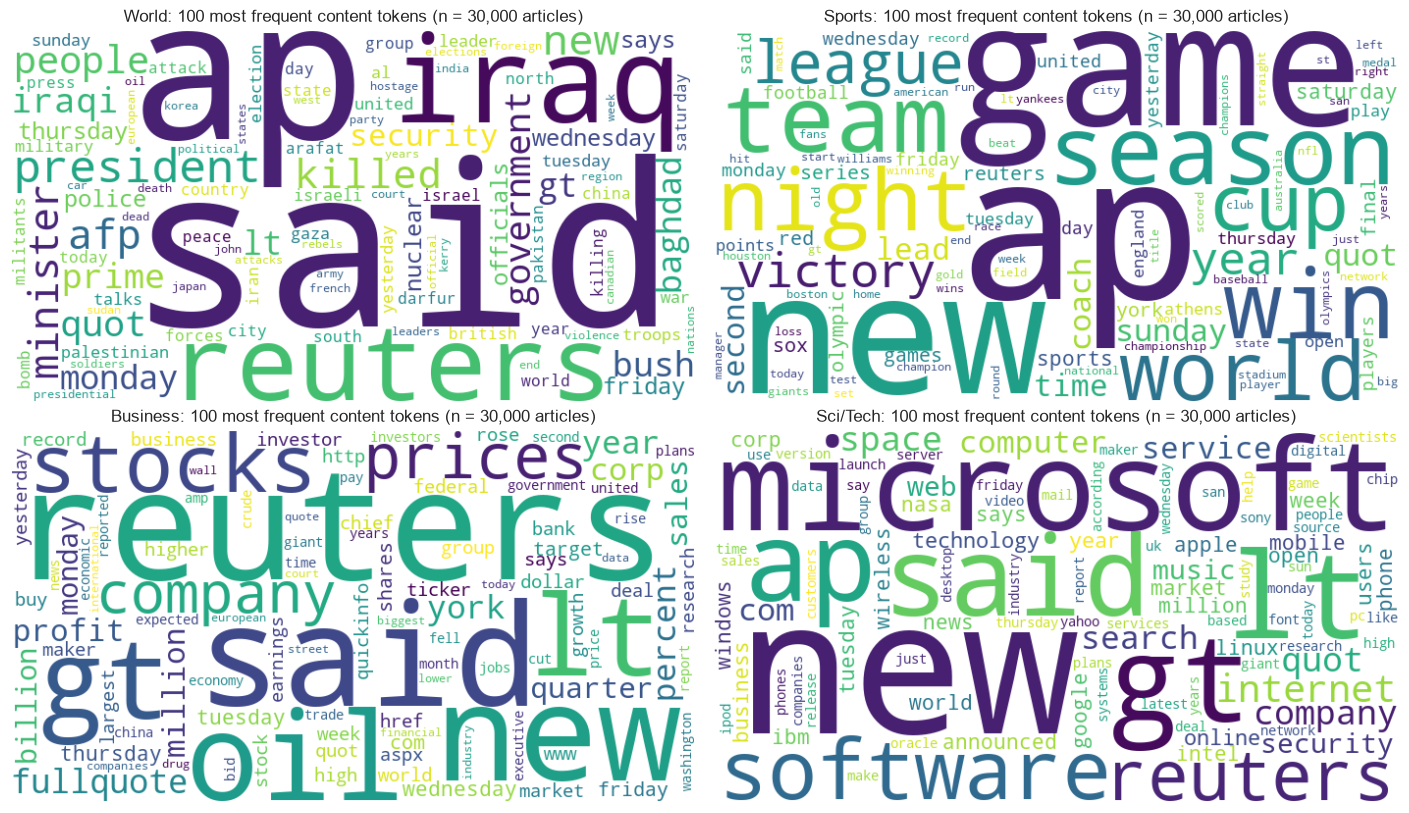

In [10]:
print(f"Top-{TOP_K} content tokens per topic (display filter: no stop words, single characters, or digit strings):")
display(top_content_words)
print(f"Jaccard overlap between topics' top-{TOP_K} content-token sets:")
display(content_top_overlap.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for ax, topic in zip(axes.ravel(), LABEL_ORDER):
    frequencies = dict(zip(content_ranks[topic]["token"], content_ranks[topic]["frequency"]))
    cloud = WordCloud(
        width=700, height=380, background_color="white", max_words=100,
        random_state=RANDOM_STATE, collocations=False,
    ).generate_from_frequencies(frequencies)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"{topic}: 100 most frequent content tokens (n = {int((train['topic'] == topic).sum()):,} articles)")
    ax.axis("off")
plt.show()

Whole-topic TTR (different N per topic; reference only):


,articles,tokens_N,types_V,ttr,hapax_share_of_types
World,30000,1190586,31010,0.0260,0.3475
Sports,30000,1169796,32234,0.0276,0.3460
Business,30000,1203078,29061,0.0242,0.3435
Sci/Tech,30000,1170496,34556,0.0295,0.3525


TTR at fixed token budgets, 20 seeded draws per topic and budget:


topic,World,Sports,Business,Sci/Tech
budget_N,,,,
10000,0.2964,0.3013,0.2789,0.3134
100000,0.1079,0.1122,0.1001,0.1181
1000000,0.0290,0.0304,0.0271,0.0325


topic,World,Sports,Business,Sci/Tech
budget_N,,,,
10000,0.00552,0.00458,0.00585,0.00565
100000,0.00104,0.00084,0.00111,0.00059
1000000,0.00007,0.00005,0.00004,0.00006


,between-topic range / largest within-topic SD,budget / smallest topic N
10000,5.9,0.009
100000,16.2,0.085
1000000,74.8,0.855


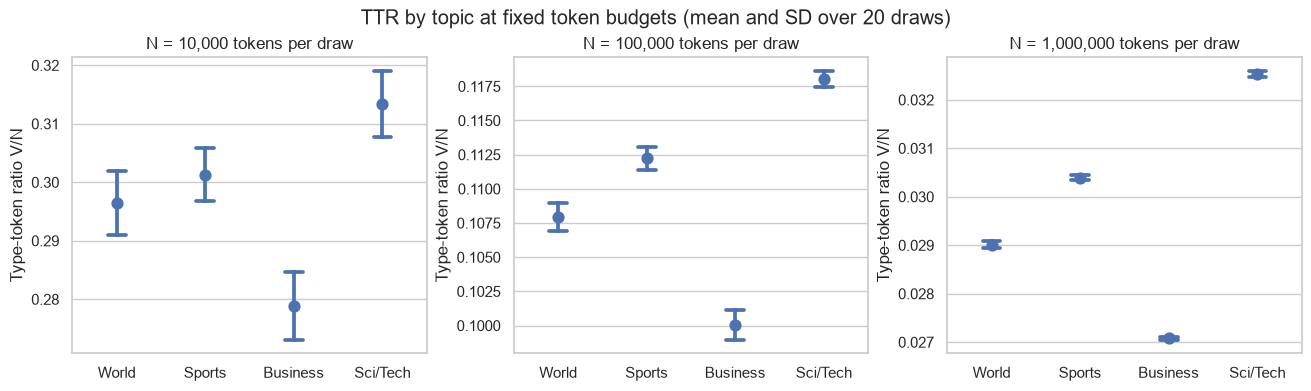

In [11]:
TTR_BUDGETS = [10_000, 100_000, 1_000_000]
TTR_DRAWS = 20
ttr_rng = np.random.default_rng(RANDOM_STATE)

topic_documents = {t: train_tokens[train["topic"] == t].tolist() for t in LABEL_ORDER}
whole_topic_ttr = pd.DataFrame(
    {
        t: {
            "articles": len(docs),
            "tokens_N": sum(len(d) for d in docs),
            "types_V": len(topic_counts[t]),
            "ttr": type_token_ratio([tok for d in docs for tok in d]),
            "hapax_share_of_types": sum(1 for c in topic_counts[t].values() if c == 1) / len(topic_counts[t]),
        }
        for t, docs in topic_documents.items()
    }
).T
assert max(TTR_BUDGETS) <= whole_topic_ttr["tokens_N"].min()

ttr_draws = pd.DataFrame(
    [
        {"topic": t, "budget_N": budget, "draw": i, "ttr": value}
        for budget in TTR_BUDGETS
        for t in LABEL_ORDER
        for i, value in enumerate(sampled_ttr(topic_documents[t], budget, ttr_rng, draws=TTR_DRAWS))
    ]
).astype({"topic": pd.CategoricalDtype(LABEL_ORDER)})
ttr_by_budget = ttr_draws.groupby(["budget_N", "topic"], observed=True)["ttr"]
budget_ttr = ttr_by_budget.agg(["mean", "std", "min", "max"]).unstack("topic")
# Draws reuse one topic's articles, so their SD measures sampling order, not corpus-to-corpus variation.
ttr_spread_ratio = (
    (budget_ttr["mean"].max(axis=1) - budget_ttr["mean"].min(axis=1)) / budget_ttr["std"].max(axis=1)
).rename("between-topic range / largest within-topic SD")
budget_share_of_topic = pd.Series(
    {b: b / whole_topic_ttr["tokens_N"].min() for b in TTR_BUDGETS}, name="budget / smallest topic N"
)

print("Whole-topic TTR (different N per topic; reference only):")
display(whole_topic_ttr.astype({"articles": int, "tokens_N": int, "types_V": int}).round(4))
print(f"TTR at fixed token budgets, {TTR_DRAWS} seeded draws per topic and budget:")
display(budget_ttr["mean"].round(4))
display(budget_ttr["std"].round(5))
display(pd.concat([ttr_spread_ratio.round(1), budget_share_of_topic.round(3)], axis=1))

fig, axes = plt.subplots(1, len(TTR_BUDGETS), figsize=(13, 3.8), constrained_layout=True)
for ax, budget in zip(axes, TTR_BUDGETS):
    sns.pointplot(data=ttr_draws[ttr_draws["budget_N"] == budget], x="topic", y="ttr", order=LABEL_ORDER,
                  errorbar="sd", linestyle="none", capsize=0.2, ax=ax)
    ax.set_title(f"N = {budget:,} tokens per draw")
    ax.set_xlabel("")
    ax.set_ylabel("Type-token ratio V/N")
fig.suptitle(f"TTR by topic at fixed token budgets (mean and SD over {TTR_DRAWS} draws)")
plt.show()

**Raw frequencies.** Function words make up {eval}`f"{top_stop_word_share.min():.0%}"` to {eval}`f"{top_stop_word_share.max():.0%}"` of each topic's raw top-50 tokens, so the raw tables describe English as much as the topics. The markup residue measured above ranks high as well: the token `39` from `#39;` is rank {eval}`int(markup_token_ranks.loc['39', 'rank'])` in the whole training corpus and appears in every topic's top ten, together with `s`, the possessive it leaves behind. `quot`, `lt`, and `gt` rank {eval}`int(markup_token_ranks.loc['quot', 'rank'])`, {eval}`int(markup_token_ranks.loc['lt', 'rank'])`, and {eval}`int(markup_token_ranks.loc['gt', 'rank'])`. Wire-service names (`reuters`, `ap`, `afp`) are among the most frequent tokens of several topics.

**Content tokens.** Once stop words are hidden, the topics are easy to tell apart. World is dominated by `iraq`, `president`, `minister`, and `killed`; Sports by `game`, `season`, `team`, and `win`; Business by `oil`, `stocks`, `prices`, and `company`; Sci/Tech by `microsoft`, `software`, `internet`, and `space`. The topics' top-50 content-token sets overlap little (Jaccard {eval}`f"{content_top_overlap.where(~np.eye(len(LABEL_ORDER), dtype=bool)).min().min():.2f}"` to {eval}`f"{content_top_overlap.where(~np.eye(len(LABEL_ORDER), dtype=bool)).max().max():.2f}"`), and the largest overlap is Business with Sci/Tech ({eval}`f"{content_top_overlap.loc['Business', 'Sci/Tech']:.2f}"`), through shared terms such as `company`, `corp`, `market`, and `million`. This is the same boundary on which most near-duplicate label conflicts fall. The content view still shows residue and source words: `quot` appears in all four topics' lists and `gt` and `lt` in three, and Business includes link fragments (`fullquote`, `href`, `aspx`, `quickinfo`, `ticker`, `http`, `www`) from escaped Reuters quote links. Weekday names appear in every topic because news is dated, not because they indicate a topic. The word clouds show the same picture: `said`, `new`, `ap`, and `reuters` are drawn as large as the most topical words.

**Type-token ratio.** Whole-topic TTR ranges from {eval}`f"{whole_topic_ttr['ttr'].min():.4f}"` to {eval}`f"{whole_topic_ttr['ttr'].max():.4f}"`. At every fixed budget the mean order is the same: Sci/Tech has the highest TTR, followed by Sports, World, and Business, although the World and Sports draws overlap at 10,000 tokens. At $N$ = 10,000 the gap between the highest and lowest topic is {eval}`f"{ttr_spread_ratio.loc[10_000]:.1f}"` times the largest between-draw standard deviation. Sci/Tech news therefore uses the most varied vocabulary for the same amount of text, plausibly because of product and company names, while Business repeats a narrower set of market terms. The draw-to-draw spread is not a confidence interval for the topic: every draw resamples the same 30,000 articles, and at $N$ = 1,000,000 a draw contains {eval}`f"{budget_share_of_topic.loc[1_000_000]:.0%}"` of the smallest topic's tokens, so draws are nearly identical by construction. The 10,000-token budget is the most informative about sampling variability. TTR also counts digit strings and markup fragments as types, so part of each topic's ratio reflects numbers and residue rather than vocabulary; the falling TTR across budgets is the dependence on $N$ that makes whole-topic values unsuitable for comparison.

## Examine the Zipf distribution

Zipf's law states that a word's frequency is roughly inversely proportional to a power of its frequency rank:

$$
f(r) \approx C \, r^{-s}, \qquad \log_{10} f(r) \approx \log_{10} C - s \log_{10} r,
$$

where $r$ is the rank (1 for the most frequent type), $f(r)$ the token count of the type at that rank, $C$ a constant, and $s$ the exponent, classically close to 1 for natural-language text. On log-log axes the relationship is a straight line with slope $-s$. A large $s$ means usage concentrates on a few very common types; a small $s$ means frequencies fall off slowly.

**Ranking and ties.** Types from the training corpus under the token convention above are ordered by descending frequency, with ties broken alphabetically, and receive distinct ranks $1, \dots, V$. All counts are positive, so no logarithm is undefined.

**Fit interval and weighting.** The exponent is estimated by least squares on the log-log points with ranks from `ZIPF_MIN_RANK` = 10 to the last rank whose frequency is at least `ZIPF_MIN_FREQUENCY` = 10. The first ten ranks are function words, where text typically flattens below a power law. Below a frequency of ten, frequencies form a staircase of large ties: thousands of types share each low count, their order within a tie is arbitrary, and counts that small are noisy.

Ranks are integers, so a decade of rank such as 1,000 to 10,000 contributes ten times as many points as the decade before it. An ordinary fit over every rank is therefore dominated by the highest decade in the interval. The main fit instead uses the ranks nearest to `ZIPF_LOG_POINTS` = 200 positions spaced evenly in $\log_{10} r$, which weights each decade about equally; the all-rank fit is shown beside it for comparison. Fits over successive decades, also on log-spaced ranks, show where the slope changes, and the same rule applied to each topic shows whether the pattern is specific to one topic.

The fitted $R^2$ measures straightness within the chosen interval only. A high value does not show that the data follow a power law, and least squares on log-log points is a descriptive estimate rather than a maximum-likelihood fit.

In [12]:
ZIPF_MIN_RANK = 10
ZIPF_MIN_FREQUENCY = 10
ZIPF_LOG_POINTS = 200

corpus_ranks = rank_frequency(corpus_counts)
vocabulary_size = len(corpus_ranks)
ZIPF_MAX_RANK = int(corpus_ranks.loc[corpus_ranks["frequency"] >= ZIPF_MIN_FREQUENCY, "rank"].max())
zipf_fit = fit_zipf(corpus_ranks, ZIPF_MIN_RANK, ZIPF_MAX_RANK, log_points=ZIPF_LOG_POINTS)
zipf_fit_all_ranks = fit_zipf(corpus_ranks, ZIPF_MIN_RANK, ZIPF_MAX_RANK)
zipf_fit_comparison = pd.DataFrame(
    {"log-spaced ranks (main)": zipf_fit, "every rank": zipf_fit_all_ranks}
).T.astype({"min_rank": int, "max_rank": int, "n_points": int})

decade_edges = [1, 10, 100, 1_000, 10_000, vocabulary_size]
zipf_by_rank_range = pd.DataFrame(
    [fit_zipf(corpus_ranks, low, high, log_points=ZIPF_LOG_POINTS) for low, high in zip(decade_edges[:-1], decade_edges[1:])]
).astype({"min_rank": int, "max_rank": int, "n_points": int})


def topic_fit(topic):
    ranks = topic_ranks[topic]
    max_rank = int(ranks.loc[ranks["frequency"] >= ZIPF_MIN_FREQUENCY, "rank"].max())
    return fit_zipf(ranks, ZIPF_MIN_RANK, max_rank, log_points=ZIPF_LOG_POINTS)


zipf_by_topic = pd.DataFrame({t: topic_fit(t) for t in LABEL_ORDER}).T.astype(
    {"min_rank": int, "max_rank": int, "n_points": int}
)
hapax_types = int((corpus_ranks["frequency"] == 1).sum())
hapax_type_share = hapax_types / vocabulary_size
top_10_token_share = corpus_ranks["frequency"].head(10).sum() / corpus_ranks["frequency"].sum()
frequent_types = corpus_ranks["frequency"] >= ZIPF_MIN_FREQUENCY
frequent_type_share = float(frequent_types.mean())
frequent_token_coverage = corpus_ranks.loc[frequent_types, "frequency"].sum() / corpus_ranks["frequency"].sum()

print(f"Vocabulary size V = {vocabulary_size:,} types; tokens N = {corpus_ranks['frequency'].sum():,}")
print(f"Types occurring once: {hapax_types:,} ({hapax_type_share:.1%} of types)")
print(f"Share of all tokens taken by the 10 most frequent types: {top_10_token_share:.1%}")
print(
    f"Types with frequency >= {ZIPF_MIN_FREQUENCY}: {frequent_type_share:.1%} of types, "
    f"covering {frequent_token_coverage:.1%} of tokens"
)
print(f"Main fit over ranks {ZIPF_MIN_RANK} to {ZIPF_MAX_RANK:,}:")
display(zipf_fit_comparison.round(4))
print("Fits over successive rank ranges (log-spaced ranks):")
display(zipf_by_rank_range.round(4))
print("Main-rule fits per topic:")
display(zipf_by_topic.round(4))

Vocabulary size V = 67,670 types; tokens N = 4,733,956
Types occurring once: 22,262 (32.9% of types)
Share of all tokens taken by the 10 most frequent types: 19.0%
Types with frequency >= 10: 29.4% of types, covering 97.4% of tokens
Main fit over ranks 10 to 19,904:


,min_rank,max_rank,n_points,slope,exponent,intercept,r_squared
log-spaced ranks (main),10,19904,191,-1.0045,1.0045,5.6911,0.9811
every rank,10,19904,19895,-1.3352,1.3352,6.8436,0.9723


Fits over successive rank ranges (log-spaced ranks):


,min_rank,max_rank,n_points,slope,exponent,intercept,r_squared
0,1,10,10,-0.6829,0.6829,5.3468,0.9348
1,10,100,90,-0.8861,0.8861,5.4222,0.9937
2,100,1000,200,-0.8227,0.8227,5.3216,0.9981
3,1000,10000,200,-1.2759,1.2759,6.7088,0.9924
4,10000,67670,200,-2.0700,2.0700,9.8506,0.9867


Main-rule fits per topic:


,min_rank,max_rank,n_points,slope,exponent,intercept,r_squared
World,10,7963,187,-0.9809,0.9809,5.0796,0.9857
Sports,10,8126,187,-0.9872,0.9872,5.0878,0.9884
Business,10,7542,187,-1.0175,1.0175,5.1892,0.9863
Sci/Tech,10,8473,188,-0.9683,0.9683,5.0397,0.9881


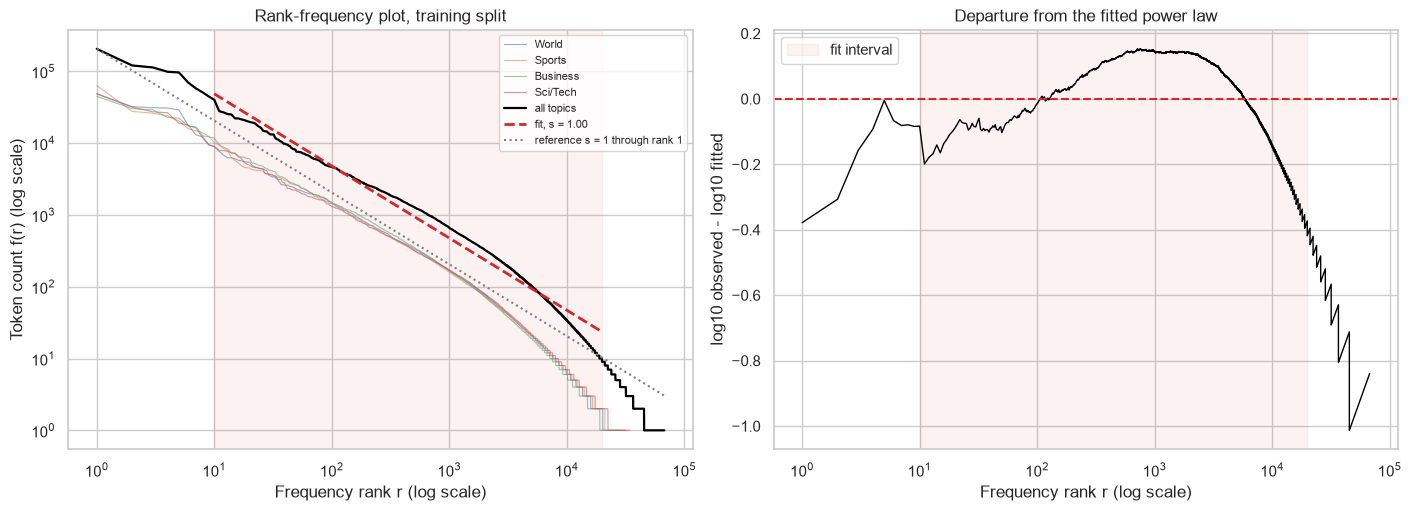

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
ax = axes[0]
for topic in LABEL_ORDER:
    ax.loglog(topic_ranks[topic]["rank"], topic_ranks[topic]["frequency"], lw=0.8, alpha=0.6, label=topic)
ax.loglog(corpus_ranks["rank"], corpus_ranks["frequency"], color="black", lw=1.6, label="all topics")
fit_ranks = np.array([ZIPF_MIN_RANK, ZIPF_MAX_RANK], dtype=float)
ax.loglog(fit_ranks, 10 ** (zipf_fit["intercept"] + zipf_fit["slope"] * np.log10(fit_ranks)),
          color="tab:red", ls="--", lw=2, label=f"fit, s = {zipf_fit['exponent']:.2f}")
anchor = corpus_ranks["frequency"].iloc[0]
all_ranks = np.array([1, vocabulary_size], dtype=float)
ax.loglog(all_ranks, anchor / all_ranks, color="grey", ls=":", label="reference s = 1 through rank 1")
ax.axvspan(ZIPF_MIN_RANK, ZIPF_MAX_RANK, color="tab:red", alpha=0.06)
ax.set_xlabel("Frequency rank r (log scale)")
ax.set_ylabel("Token count f(r) (log scale)")
ax.set_title("Rank-frequency plot, training split")
ax.legend(fontsize=8)

ax = axes[1]
log_rank = np.log10(corpus_ranks["rank"])
residual = np.log10(corpus_ranks["frequency"]) - (zipf_fit["intercept"] + zipf_fit["slope"] * log_rank)
ax.plot(corpus_ranks["rank"], residual, color="black", lw=1)
ax.axhline(0, color="tab:red", ls="--")
ax.axvspan(ZIPF_MIN_RANK, ZIPF_MAX_RANK, color="tab:red", alpha=0.06, label="fit interval")
ax.set_xscale("log")
ax.set_xlabel("Frequency rank r (log scale)")
ax.set_ylabel("log10 observed - log10 fitted")
ax.set_title("Departure from the fitted power law")
ax.legend()
plt.show()

The training corpus has $V$ = {eval}`f"{vocabulary_size:,}"` types and $N$ = {eval}`f"{int(corpus_ranks['frequency'].sum()):,}"` tokens. Usage is highly concentrated: the ten most frequent types account for {eval}`f"{top_10_token_share:.1%}"` of all tokens, while {eval}`f"{hapax_type_share:.1%}"` of types occur only once. Types seen at least {eval}`ZIPF_MIN_FREQUENCY` times are only {eval}`f"{frequent_type_share:.1%}"` of the vocabulary but cover {eval}`f"{frequent_token_coverage:.1%}"` of tokens, so a minimum-frequency cutoff can shrink a vocabulary several-fold while losing few tokens.

With log-spaced ranks, the main fit over ranks {eval}`ZIPF_MIN_RANK` to {eval}`f"{ZIPF_MAX_RANK:,}"` gives $s$ = {eval}`f"{zipf_fit['exponent']:.3f}"` with $R^2$ = {eval}`f"{zipf_fit['r_squared']:.3f}"`, close to the classical exponent of 1. The same interval fitted on every rank gives $s$ = {eval}`f"{zipf_fit_all_ranks['exponent']:.3f}"`, because the fit is then dominated by the thousands of high ranks. A weighting choice alone changes the exponent by about a third, so a single fitted exponent should not be reported without its interval and weighting.

The curve is not one straight line. Fitted decade by decade (`zipf_by_rank_range`), the exponent is {eval}`f"{zipf_by_rank_range['exponent'].iloc[0]:.2f}"` for ranks 1 to 10, between {eval}`f"{zipf_by_rank_range['exponent'].iloc[1:3].min():.2f}"` and {eval}`f"{zipf_by_rank_range['exponent'].iloc[1:3].max():.2f}"` for ranks 10 to 1,000, {eval}`f"{zipf_by_rank_range['exponent'].iloc[3]:.2f}"` for ranks 1,000 to 10,000, and {eval}`f"{zipf_by_rank_range['exponent'].iloc[-1]:.2f}"` beyond rank 10,000. The curve is flatter than the fit at the head and much steeper in the tail. The residual panel shows the same thing: the departure from the main fit forms a systematic arch, positive in the middle ranks and falling steeply in the tail, rather than scatter around zero. A high $R^2$ therefore coexists with a clear misfit. The flat head is typical of the most frequent function words; here it also contains `39` and `s`, which exist only because of broken entities and the token convention. The steep tail is expected in a finite corpus: most rare words have not had the chance to appear, and below a frequency of about ten the curve becomes a staircase of tied counts.

The four topics follow nearly the same law: the per-topic exponents lie between {eval}`f"{zipf_by_topic['exponent'].min():.2f}"` and {eval}`f"{zipf_by_topic['exponent'].max():.2f}"` (`zipf_by_topic`), each over a shorter interval because a smaller corpus reaches frequency ten at a lower rank. AG News therefore follows Zipf's law approximately in its middle ranks, with an exponent near 1, but not as an exact power law over its whole range. The estimate depends on the token convention, the corpus size, the fit interval, and the weighting, all of which are recorded above.

## Implications for preprocessing

The audit gives the preprocessing chapter a measured starting point:

- **Repair before normalizing.** About a quarter of articles contain entities that lost their `&`, a tenth contain literal backslashes, and escaped links add long runs of link fragments. These produce frequent tokens such as `39`, `s`, `quot`, `lt`, and `gt` under any tokenizer, so the normalization comparison should measure how much each repair changes the vocabulary and token counts relative to this raw baseline.
- **Some assignment steps have little to act on.** Mentions and hashtags are essentially absent, and URLs appear in under 2% of articles. Those steps should be implemented and measured, but a small effect is the expected result here, not evidence that the steps are useless in general.
- **Source markers are a possible shortcut.** Wire tags differ strongly by topic, so representations that keep them can partly classify by source.
- **Length is not a concern.** Topic length differences are statistically detectable but practically negligible, and the articles are short.
- **Rare words dominate the vocabulary but not the text.** A third of the types occur once, so vectorizer vocabularies and OOV rates will depend heavily on frequency cutoffs and on whether residue is repaired.
- **Scores have a ceiling and some optimism.** Near-identical articles with different topics limit attainable accuracy, and about one test article in nine has a near-copy in training.

These findings come from the raw text under one descriptive token convention. The preprocessing chapter's tokenizers and cleaning steps will change the counts, which is the effect that chapter measures.